# GSE139404

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2020-09-17
> - Modified: 2026-04-11

# 1. Experimental Design

> Genome-wide open chromatin methylome profiles in colorectal cancer
> - Homo sapiens
> - GPL13534: Illumina Infinium HumanMethylation450 BeadChip
> - Beijing Institute of Genomics, Chinese Academy of Sciences
> - Fan, J., Li, J., Guo, S. et al. Genome-wide DNA methylation profiles of low- and high-grade adenoma reveals potential biomarkers for early detection of colorectal carcinoma. Clin Epigenet 12, 56 (2020). https://doi.org/10.1186/s13148-020-00851-3.

| Sample | Tissue | Status | Replicate |
| - | - | - | - |
| Normal | Colon adjacent normal | normal | rep1~20 |
| LGA | Colon cancer tissue | low-grade adenoma | rep1~18 |
| HGA | Colon cancer tissue | high-grade adenoma | rep1~22 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(minfi))
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(DMRcate))
suppressPackageStartupMessages(library(IlluminaHumanMethylation450kmanifest))
suppressPackageStartupMessages(library(IlluminaHumanMethylation450kanno.ilmn12.hg19))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 2. Download Data

In [2]:
suppressPackageStartupMessages(library(GEOquery))

In [3]:
gse_id <- "GSE139404"
data_dir <- file.path("~/dataset_1/methylation_dataset/array", gse_id)
dir.create(data_dir, showWarnings = FALSE)

In [4]:
getGEOSuppFiles(GEO = gse_id, makeDirectory = FALSE, baseDir = data_dir)

,size,isdir,mode,mtime,ctime,atime,uid,gid,uname,grname,fname,destdir,filepath,GEO
,<dbl>,<lgl>,<octmode>,<dttm>,<dttm>,<dttm>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
~/dataset_1/methylation_dataset/array/GSE139404/GSE139404_RAW.tar,706570240,FALSE,777,2026-04-11 17:36:59,2026-04-11 17:36:59,2026-04-11 17:36:59,1000,1000,fugui,fugui,GSE139404_RAW.tar,~/dataset_1/methylation_dataset/array/GSE139404,~/dataset_1/methylation_dataset/array/GSE139404/GSE139404_RAW.tar,GSE139404


In [5]:
file.path(data_dir, paste0(gse_id, "_RAW.tar")) |>
    path.expand() |>
    untar(exdir = path.expand(file.path(data_dir, "idat")))

In [6]:
list.files(file.path(data_dir, "idat"), pattern = "idat.gz$", full = TRUE) |>
    lapply(FUN = R.utils::gunzip, overwrite = TRUE) |>
    invisible()

In [7]:
mSet <- getGEO(
    GEO = gse_id, destdir = data_dir,
    AnnotGPL = TRUE, getGPL = FALSE)[[1]]
mSet

Found 1 file(s)

GSE139404_series_matrix.txt.gz



ExpressionSet (storageMode: lockedEnvironment)
assayData: 485577 features, 60 samples 
  element names: exprs 
protocolData: none
phenoData
  sampleNames: GSM4140633 GSM4140634 ... GSM4140737 (60 total)
  varLabels: title geo_accession ... tissue:ch1 (37 total)
  varMetadata: labelDescription
featureData: none
experimentData: use 'experimentData(object)'
  pubMedIds: 32317010 
Annotation: GPL13534 

In [8]:
pData(mSet) |> select(
    Sample_Name = geo_accession, full_filenames = `supplementary_file.1`, 
    Sample_Group = `disease:ch1`, Sample_Gender = `gender:ch1`) |>
    mutate(
        full_filenames = basename(full_filenames),
        Sentrix_ID = str_extract(full_filenames, "\\d{10}"),
        Sentrix_Position = str_extract(full_filenames, "R\\d{2}C\\d{2}"),
        Basename = str_remove(full_filenames, "_Red\\.idat\\.gz$"),
        Sample_Group = case_when(
            str_detect(Sample_Group, "normal") ~ "Normal",
            str_detect(Sample_Group, "low-grade adenoma") ~ "LGA",
            str_detect(Sample_Group, "high-grade adenoma") ~ "HGA")) |>
    select(
        Sample_Name, Sample_Group, Sample_Gender, 
        Sentrix_ID, Sentrix_Position, Basename) |>
    write_csv(file.path(data_dir, "idat", "SampleSheet.csv"))

# 3. minfi

> - Martin J. Aryee, Andrew E. Jaffe, Hector Corrada-Bravo, Christine Ladd-Acosta, Andrew P. Feinberg, Kasper D. Hansen, Rafael A. Irizarry, Minfi: a flexible and comprehensive Bioconductor package for the analysis of Infinium DNA methylation microarrays, Bioinformatics, Volume 30, Issue 10, May 2014, Pages 1363–1369, https://doi.org/10.1093/bioinformatics/btu049

## 1). Data Import

In [9]:
sample_sheet <- file.path(data_dir, "idat") |>
    read.metharray.sheet(verbose = FALSE) |>
    mutate(
        Sample_Group = factor(
            Sample_Group, levels = c("Normal", "LGA", "HGA"))) |>
    arrange(Sample_Group) |> 
    group_by(Sample_Group) |> 
    mutate(Sample_Replicate = paste0("rep", row_number())) |>
    ungroup()

sample_sheet |> select(-Basename) |> head()

Sample_Name,Sample_Group,Sample_Gender,Array,Slide,Sample_Replicate
<chr>,<fct>,<chr>,<chr>,<chr>,<chr>
GSM4140634,Normal,female,R02C01,3999442103,rep1
GSM4140637,Normal,female,R05C01,3999442103,rep2
GSM4140640,Normal,female,R02C02,3999442103,rep3
GSM4140643,Normal,male,R05C02,3999442103,rep4
GSM4140645,Normal,male,R01C01,3999442051,rep5
GSM4140647,Normal,female,R03C01,3999442051,rep6


In [10]:
rgSet <- read.metharray.exp(targets = sample_sheet)
# Set a descriptive name for the samples.
sampleNames(rgSet) <- paste0(
    rgSet$Sample_Group, "_", rgSet$Sample_Replicate)
rgSet

Warning message:
"Setting row names on a tibble is deprecated."


class: RGChannelSet 
dim: 622399 60 
metadata(0):
assays(2): Green Red
rownames(622399): 10600313 10600322 ... 74810490 74810492
rowData names(0):
colnames(60): Normal_rep1 Normal_rep2 ... HGA_rep21 HGA_rep22
colData names(8): Sample_Name Sample_Group ... Sample_Replicate
  filenames
Annotation
  array: IlluminaHumanMethylation450k
  annotation: ilmn12.hg19

## 2). Quality Control

### Detection Probe

In [11]:
# Detection p-values for all probed genomic positions.
detP <- detectionP(rgSet)

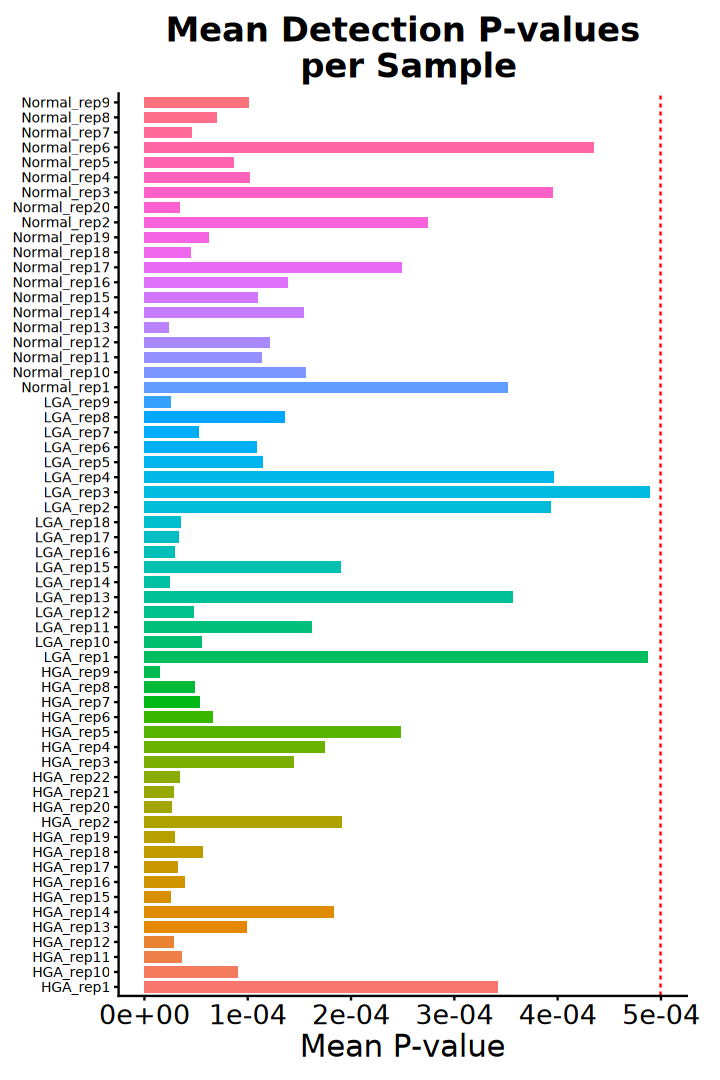

In [12]:
options(repr.plot.width = 6, repr.plot.height = 9)

data.frame(
    Sample = colnames(detP), 
    MeanDetP = colMeans(detP)) |>
    arrange(MeanDetP) |>
    ggplot(aes(x = Sample, y = MeanDetP)) +
        geom_bar(aes(fill = Sample), stat = "identity", width = 0.7) +
        geom_hline(yintercept = 5e-04, linetype = "dashed", color = "red") +
        scale_y_continuous(labels = scales::label_scientific()) +
        coord_flip() +
        labs(title = "Mean Detection P-values\n per Sample",
            x = NULL, y = "Mean P-value") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = margin(t = 10, r = 20, b = 10, l = 10),
            legend.position = "none",
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text.x = element_text(size = 16), 
            axis.text.y = element_text(size = 8), 
            panel.grid.major = element_blank())

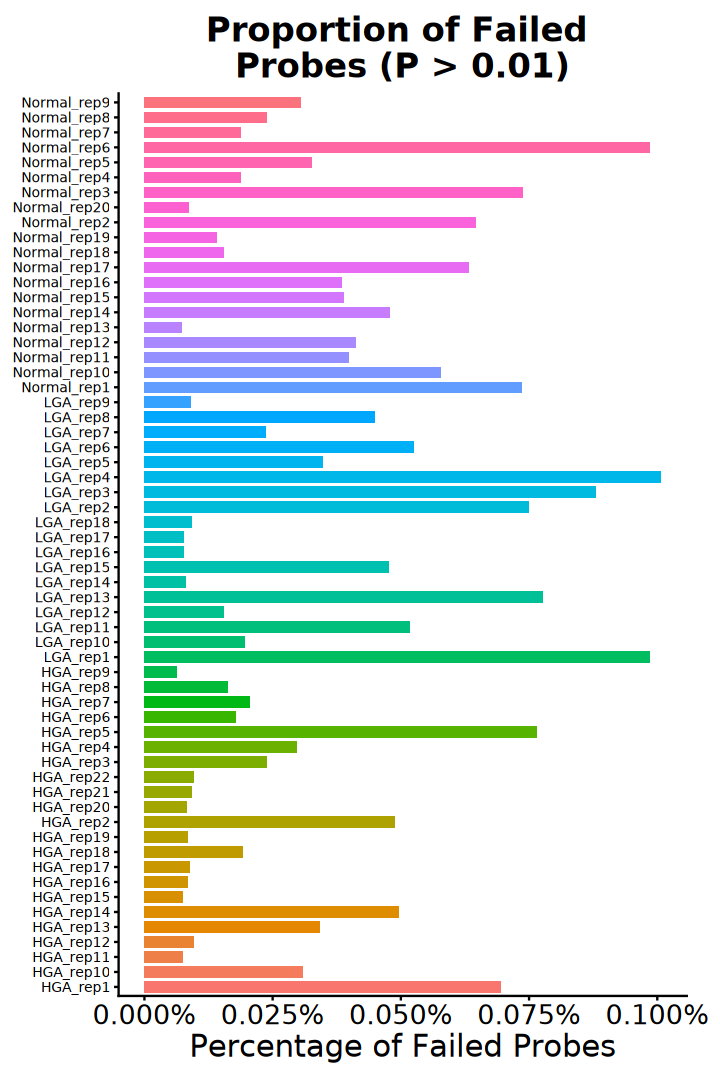

In [13]:
options(repr.plot.width = 6, repr.plot.height = 9)

data.frame(
    Sample = colnames(detP), 
    FailureRate = colSums(detP > 0.01) / nrow(detP)) |>
    arrange(FailureRate) |>
    ggplot(aes(x = Sample, y = FailureRate)) +
        geom_bar(aes(fill = Sample), stat = "identity", width = 0.7) +
        scale_y_continuous(labels = scales::percent) +
        coord_flip() +
        labs(title = "Proportion of Failed \nProbes (P > 0.01)",
            x = NULL, y = "Percentage of Failed Probes") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = margin(t = 10, r = 20, b = 10, l = 10),
            legend.position = "none",
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text.x = element_text(size = 16), 
            axis.text.y = element_text(size = 8), 
            panel.grid.major = element_blank())

### minfi QC Report

In [14]:
qcReport(
    rgSet = rgSet, sampNames = sampleNames(rgSet), 
    sampGroups = rgSet$Sample_Group,
    pdf = file.path(data_dir, "QCReport_minfi.pdf")) |>
    suppressWarnings()

agg_record_58fe43423f87 
                      2

### Visualization

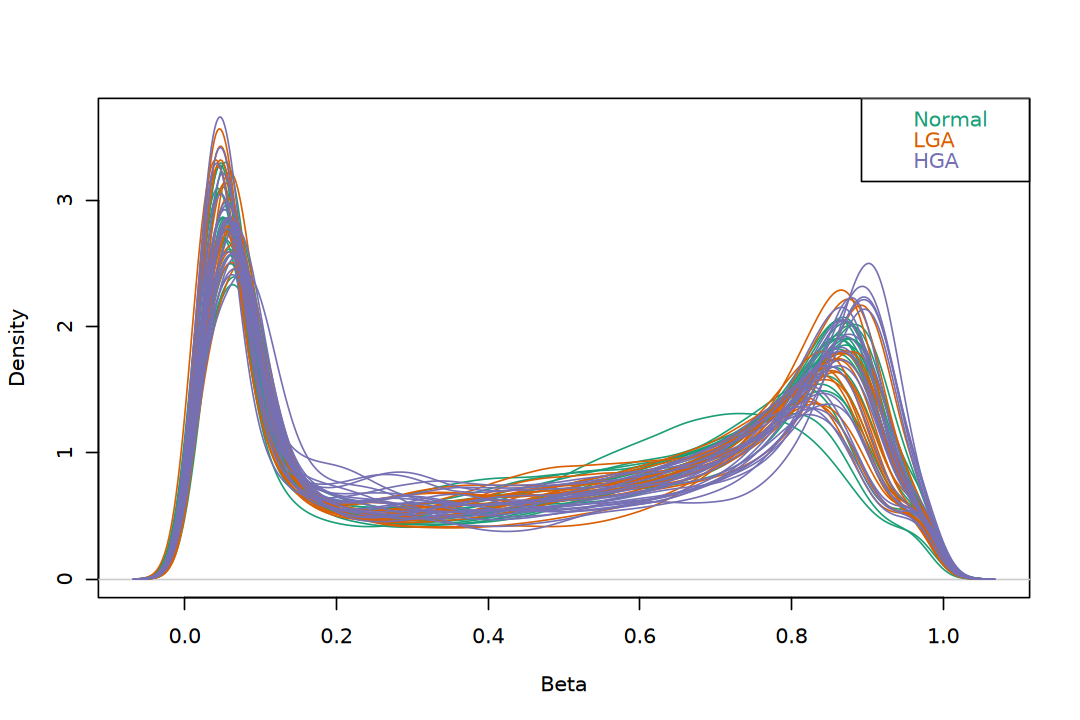

In [15]:
options(repr.plot.width = 9, repr.plot.height = 6)

densityPlot(dat = rgSet, sampGroups = rgSet$Sample_Group)

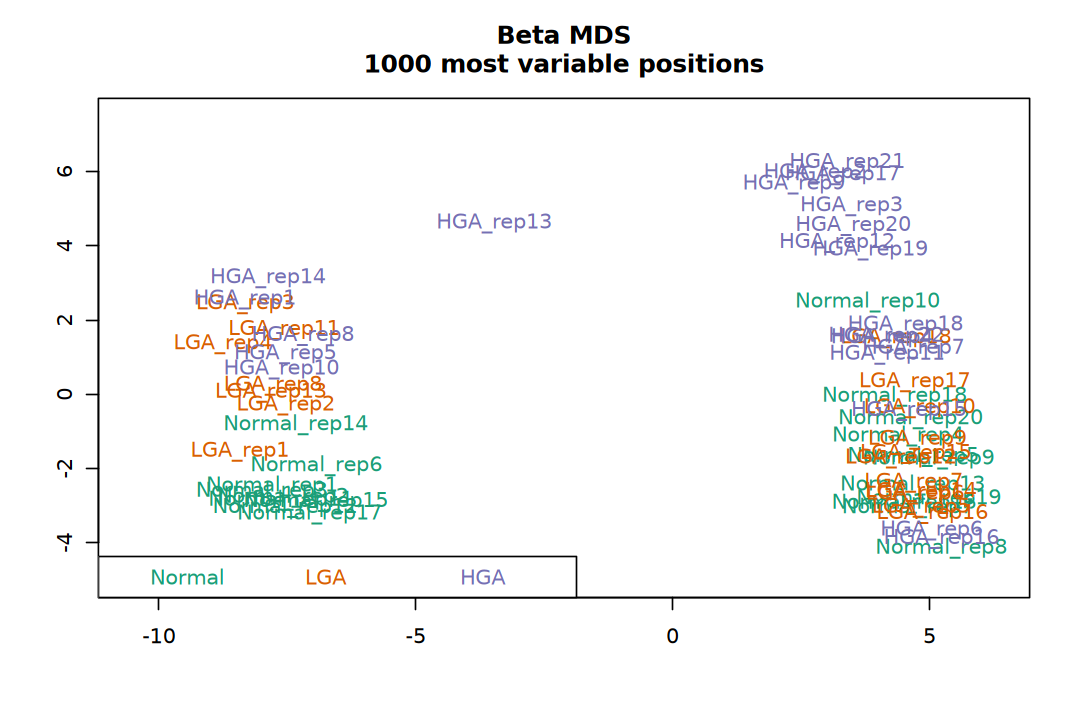

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)

mdsPlot(
    dat = rgSet, sampNames = sampleNames(rgSet), 
    sampGroups = rgSet$Sample_Group)

### minfiQC

In [17]:
# Converts the Red/Green channel into methylation signal
methySet <- preprocessRaw(rgSet)
methySet

class: MethylSet 
dim: 485512 60 
metadata(0):
assays(2): Meth Unmeth
rownames(485512): cg00050873 cg00212031 ... ch.22.47579720R
  ch.22.48274842R
rowData names(0):
colnames(60): Normal_rep1 Normal_rep2 ... HGA_rep21 HGA_rep22
colData names(8): Sample_Name Sample_Group ... Sample_Replicate
  filenames
Annotation
  array: IlluminaHumanMethylation450k
  annotation: ilmn12.hg19
Preprocessing
  Method: Raw (no normalization or bg correction)
  minfi version: 1.56.0
  Manifest version: 0.4.0

In [18]:
methySet <- minfiQC(methySet, fixOutliers = TRUE, verbose = FALSE)

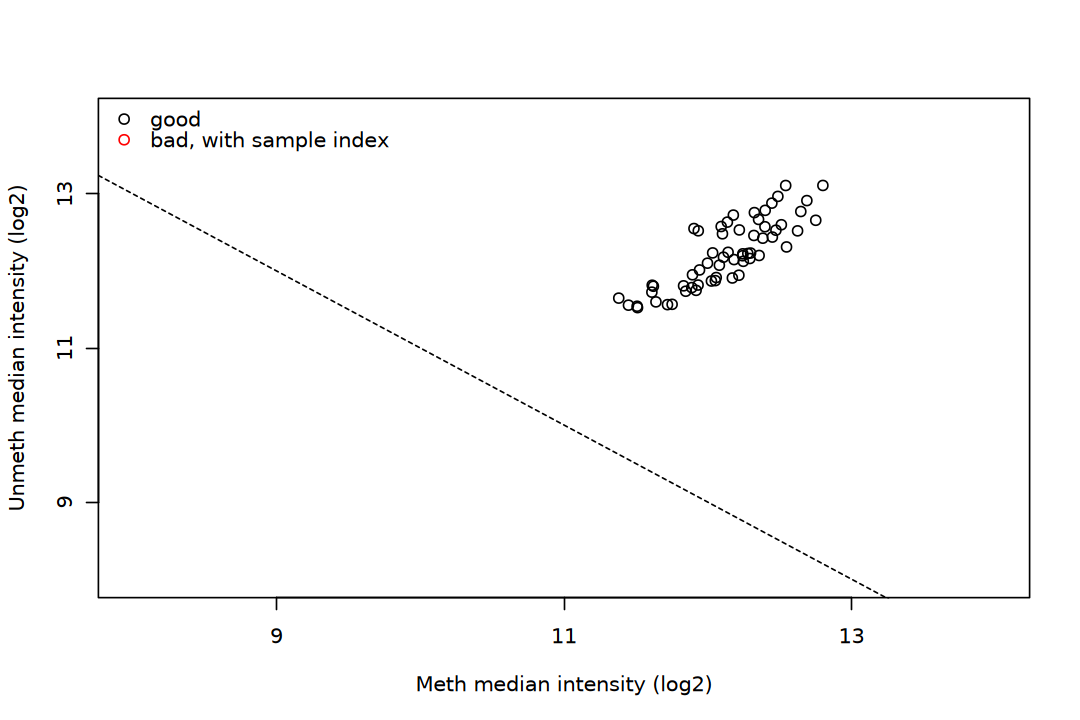

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)
plotQC(methySet$qc)

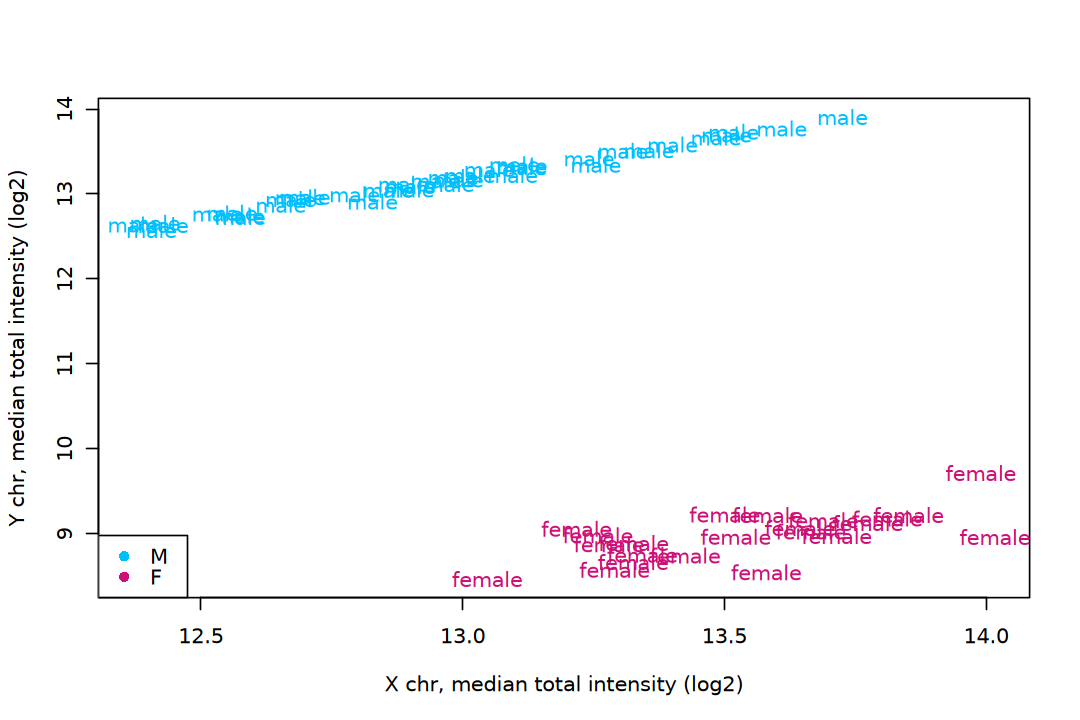

In [20]:
options(repr.plot.width = 9, repr.plot.height = 6)
plotSex(methySet$object, id = methySet$object$Sample_Gender)

## 3). Normalization

> - `preprocessFunnorm` function is most appropriate for datasets with global methylation differences such as cancer/normal or vastly different tissue types.
>   - Fortin, JP., Labbe, A., Lemire, M. et al. Functional normalization of 450k methylation array data improves replication in large cancer studies. Genome Biol 15, 503 (2014). https://doi.org/10.1186/s13059-014-0503-2

In [21]:
methySet <- preprocessFunnorm(rgSet = rgSet, verbose = FALSE)
methySet

[preprocessFunnorm] Background correction with noob



class: GenomicRatioSet 
dim: 485512 60 
metadata(0):
assays(2): Beta CN
rownames(485512): cg13869341 cg14008030 ... cg08265308 cg14273923
rowData names(0):
colnames(60): Normal_rep1 Normal_rep2 ... HGA_rep21 HGA_rep22
colData names(11): Sample_Name Sample_Group ... yMed predictedSex
Annotation
  array: IlluminaHumanMethylation450k
  annotation: ilmn12.hg19
Preprocessing
  Method: NA
  minfi version: NA
  Manifest version: NA

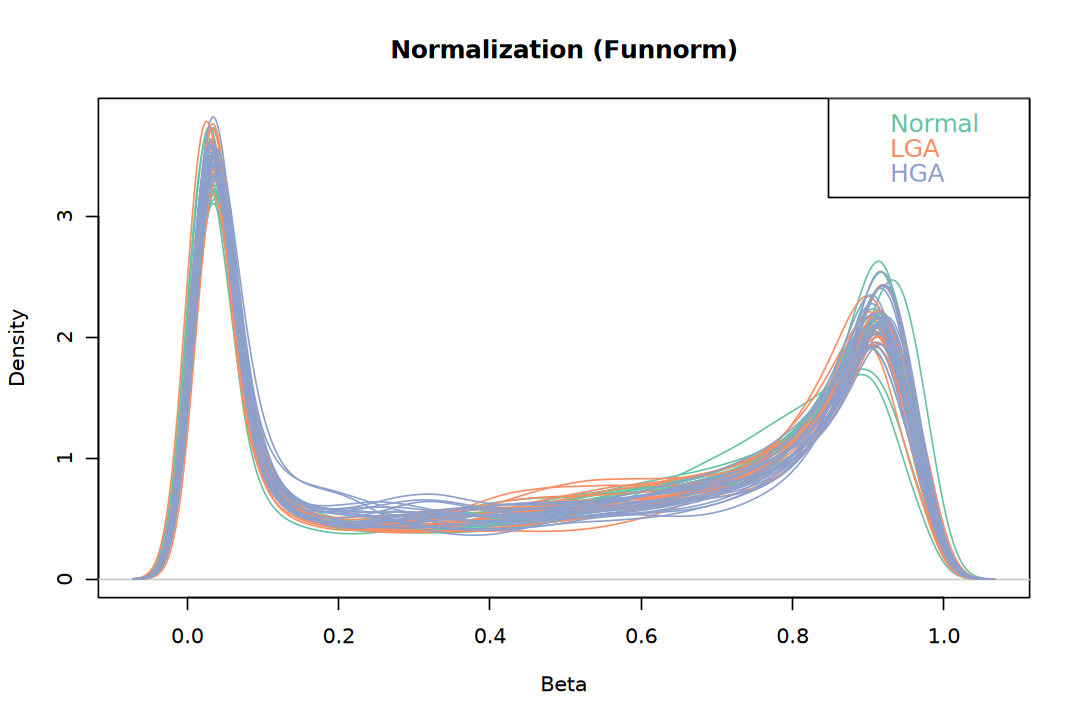

In [22]:
options(repr.plot.width = 9, repr.plot.height = 6)
densityPlot(
    dat = getBeta(methySet), 
    sampGroups = methySet$Sample_Group,
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main = "Normalization (Funnorm)")
legend("topright", legend = levels(methySet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white")

## 4). Filtering Probes

In [23]:
# remove any probes that have failed in one or more samples
detP <- detP[match(featureNames(methySet), rownames(detP)), ] 
keep <- rowSums(detP < 0.01) == ncol(methySet)
methySet_filtered <- methySet[keep, ]

In [24]:
# Calculate statistics
total_probes <- length(keep)
retained_probes <- sum(keep)
filtered_probes <- total_probes - retained_probes
filter_percentage <- (filtered_probes / total_probes) * 100

# Print summary
message("--- Probe Filtering Summary (Detection P-value > 0.01) ---")
message("Total probes starting:    ", total_probes)
message("Probes filtered out:      ", filtered_probes, " (", round(filter_percentage, 2), "%)")
message("Probes retained:          ", retained_probes)
message("---------------------------------------------------------")

--- Probe Filtering Summary (Detection P-value > 0.01) ---

Total probes starting:    485512

Probes filtered out:      2013 (0.41%)

Probes retained:          483499

---------------------------------------------------------



In [25]:
array_anno <- getAnnotation(IlluminaHumanMethylation450kanno.ilmn12.hg19)

In [26]:
# remove probes on the sex chromosomes
keep <- !(featureNames(methySet_filtered) %in% 
    array_anno$Name[array_anno$chr %in% c("chrX", "chrY")])
methySet_filtered <- methySet_filtered[keep, ]

In [27]:
# Calculate statistics
total_probes <- length(keep)
retained_probes <- sum(keep)
filtered_probes <- total_probes - retained_probes
filter_percentage <- (filtered_probes / total_probes) * 100

# Print summary
message("--- Probe Filtering Summary (Probes on sex chromosomes) ---")
message("Total probes starting:    ", total_probes)
message("Probes filtered out:      ", filtered_probes, " (", round(filter_percentage, 2), "%)")
message("Probes retained:          ", retained_probes)
message("---------------------------------------------------------")

--- Probe Filtering Summary (Probes on sex chromosomes) ---

Total probes starting:    483499

Probes filtered out:      11268 (2.33%)

Probes retained:          472231

---------------------------------------------------------



In [28]:
# remove probes with SNPs at CpG site
methySet_filtered <- dropLociWithSnps(
    methySet_filtered, snps = c("CpG", "SBE"), maf = 0)

In [29]:
# Print summary
message("--- Probe Filtering Summary (Probes affected by SNP) ---")
message("Probes retained:          ", nrow(methySet_filtered))
message("---------------------------------------------------------")

--- Probe Filtering Summary (Probes affected by SNP) ---

Probes retained:          455452

---------------------------------------------------------



In [30]:
# # exclude cross reactive probes
# reactiveProbes <- read.csv(
#     file = "~/reference/Database/Others/48639-non-specific-probes-Illumina450k.xlsx", stringsAsFactors = FALSE)

# keep <- !(featureNames(methySet_filtered) %in% reactiveProbes$TargetID)

# methySet_filtered <- methySet_filtered[keep, ]

In [31]:
# # Calculate statistics
# total_probes <- length(keep)
# retained_probes <- sum(keep)
# filtered_probes <- total_probes - retained_probes
# filter_percentage <- (filtered_probes / total_probes) * 100

# # Print summary
# message("--- Probe Filtering Summary (Cross reactive probes) ---")
# message("Total probes starting:    ", total_probes)
# message("Probes filtered out:      ", filtered_probes, " (", round(filter_percentage, 2), "%)")
# message("Probes retained:          ", retained_probes)
# message("---------------------------------------------------------")

## 5). Differentially Analysis

In [32]:
# Extract beta values (proportion of methylation at each CpG site)
# Formula: M / (M + U + 100), where M = methylated intensity, U = unmethylated intensity
# Range: 0–1, where 0 = unmethylated and 1 = fully methylated
# More intuitive and suitable for visualization
bVals <- getBeta(methySet_filtered)

# Extract M values (log2 ratio of methylated vs unmethylated intensities)
# Formula: log2(M/U)
# Range: (-Inf, +Inf), approximately homoscedastic
# Statistically more appropriate for differential methylation analysis
mVals <- getM(methySet_filtered)

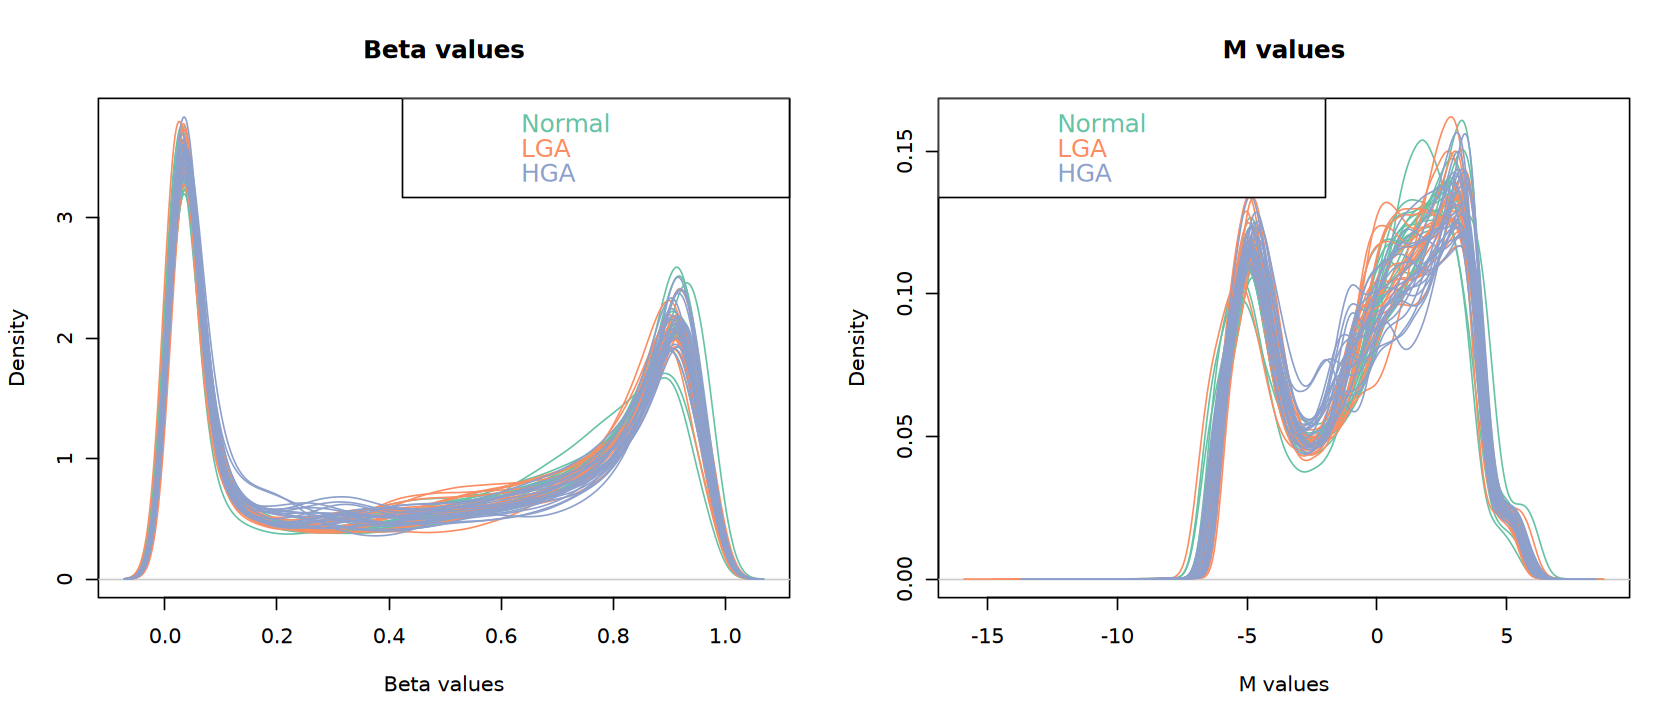

In [33]:
options(repr.plot.width = 14, repr.plot.height = 6)

par(mfrow = c(1, 2))
densityPlot(
    bVals, sampGroups = methySet$Sample_Group, 
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main="Beta values", xlab="Beta values")
legend("topright", legend = levels(methySet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

densityPlot(
    mVals, sampGroups = methySet$Sample_Group, 
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main="M values", xlab="M values")
legend("topleft", legend = levels(methySet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

In [34]:
p_cutoff <- 0.01
logFC_cutoff <- 5

### DMPs

In [35]:
dmp_results <- dmpFinder(
    getM(methySet_filtered), pheno = methySet_filtered$Sample_Group, 
    type = "categorical", qCutoff = p_cutoff, shrinkVar = FALSE)

In [36]:
head(dmp_results)

,intercept,f,pval,qval
,<dbl>,<dbl>,<dbl>,<dbl>
cg05902130,-1.7523853,50.60479,2.313658e-13,1.472736e-08
cg04438497,-3.4102889,48.71870,4.602442e-13,1.472736e-08
cg02306139,-1.1588518,48.36451,5.246767e-13,1.472736e-08
cg25095187,-0.6042269,47.96504,6.086744e-13,1.472736e-08
cg18743793,-1.8303166,46.69889,9.796088e-13,1.472736e-08
cg05603784,-0.9977399,46.66717,9.914588e-13,1.472736e-08


### DMPs (limma)

In [37]:
design <- model.matrix(
     ~ 0 + Sample_Group, data = pData(methySet_filtered))
colnames(design) <- levels(methySet_filtered$Sample_Group)

In [38]:
comparisons <- combn(
    levels(methySet_filtered$Sample_Group), 2, simplify = FALSE)
comparisons
compar_levels <- map_chr(comparisons, ~ paste0(.x[2], "_vs_", .x[1]))
compar_levels

[[1]]
[1] "Normal" "LGA"   

[[2]]
[1] "Normal" "HGA"   

[[3]]
[1] "LGA" "HGA"

[1] "LGA_vs_Normal" "HGA_vs_Normal" "HGA_vs_LGA"

In [39]:
contrast_mat <- comparisons |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_mat

,LGA-Normal,HGA-Normal,HGA-LGA
Normal,-1,-1,0
LGA,1,0,-1
HGA,0,1,1


In [40]:
fit <- lmFit(mVals, design)
fit <- contrasts.fit(fit, contrast_mat)
fit <- eBayes(fit)
dmps <- topTable(fit, coef = 2, number = Inf)

In [41]:
p_cutoff <- 0.01
logFC_cutoff <- with(dmps, mean(abs(logFC)) + 2*sd(abs(logFC)))

print(paste("p-value cutoff:", p_cutoff))
print(paste("logFC cutoff:", logFC_cutoff))

[1] "p-value cutoff: 0.01"
[1] "logFC cutoff: 1.45502485176778"


In [42]:
array_anno_sub <- array_anno[
    match(rownames(mVals), array_anno$Name), 
    c(1:4, 18:19, 24, 26)]

In [43]:
dmps_result <- topTable(
    fit, coef = 2, number = Inf, genelist = array_anno_sub) |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            pvalue < p_cutoff & logFC >  logFC_cutoff ~ "Up",
            pvalue < p_cutoff & logFC < -logFC_cutoff ~ "Down",
            TRUE ~ "NotSig") |> 
            factor(levels = c("Up", "Down", "NotSig")))

In [44]:
head(dmps_result)
table(dmps_result$result)

,chr,pos,strand,Name,Islands_Name,Relation_to_Island,UCSC_RefGene_Name,UCSC_RefGene_Group,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
cg05902130,chr14,74885106,-,cg05902130,,OpenSea,TMEM90A,5'UTR,-1.730838,-0.8574152,-10.083832,1.627902e-14,2.60282e-09,22.70674,Down
cg25095187,chr2,29335792,-,cg25095187,chr2:29337983-29338909,N_Shelf,,,-2.167068,0.4731063,-9.936378,2.840428e-14,2.60282e-09,22.16998,Down
cg02306139,chr5,148638033,+,cg02306139,,OpenSea,ABLIM3,3'UTR,-1.895446,-0.1553835,-9.805596,4.662320e-14,2.60282e-09,21.69191,Down
cg05603784,chr16,88499083,+,cg05603784,chr16:88496201-88497763,S_Shore,ZNF469,Body,-1.774089,-0.1090681,-9.762277,5.496054e-14,2.60282e-09,21.53316,Down
cg21644778,chr17,56466866,-,cg21644778,,OpenSea,RNF43,Body,-1.911547,-0.1480476,-9.715175,6.573973e-14,2.60282e-09,21.36031,Down
cg04866380,chr7,31725973,-,cg04866380,,OpenSea,C7orf16;C7orf16,TSS1500;TSS1500,-1.934351,0.4139044,-9.678959,7.545580e-14,2.60282e-09,21.22726,Down



    Up   Down NotSig 
  9902  13570 431980 

### DMRs

In [45]:
design <- model.matrix(
     ~ Sample_Group, data = pData(methySet_filtered))

In [46]:
dmr_result <- bumphunter(
    methySet_filtered, design, coef = 3, type = "M", 
    cutoff = 0.1, nullMethod = "permutation")

[bumphunterEngine] Using a single core (backend: doSEQ, version: 1.5.2).

[bumphunterEngine] Computing coefficients.

[bumphunterEngine] Finding regions.

[bumphunterEngine] Found 209468 bumps.



In [47]:
head(dmr_result$table)

,chr,start,end,value,area,cluster,indexStart,indexEnd,L,clusterL
,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>
16626,chr11,114310578,114310578,Inf,Inf,38813,285535,285535,1,11
24744,chr14,64931880,64931897,Inf,Inf,58468,331083,331084,2,12
104123,chr11,65625947,65625947,-Inf,Inf,35308,277193,277193,1,16
22764,chr13,78491982,78494462,1.516464,74.30671,53926,320046,320094,49,49
14053,chr11,44330474,44333192,1.392792,66.85402,33136,271582,271629,48,48
73678,chr7,130130187,130133110,1.135401,65.85325,175783,202486,202543,58,61


### DMRs (DMRcate)

In [48]:
design <- model.matrix(
     ~ Sample_Group, data = pData(methySet_filtered))

In [49]:
cpg_anno <- cpg.annotate(
    object = mVals, datatype = "array", what = "M", arraytype = "450K",
    annotation = c(
        array = "IlluminaHumanMethylation450kanno", 
        annotation = "ilmn12.hg19"),
    analysis.type = "differential", design = design, coef = 3)

cpg_anno

Your contrast returned 195146 individually significant probes. We recommend the default setting of pcutoff in dmrcate().



CpGannotated object describing 455452 CpG sites, with independent
CpG threshold indexed at fdr=0.05 and 195146 significant CpG sites.

In [50]:
dmrs <- dmrcate(cpg_anno, lambda = 1000, C = 2)

Fitting chr1...

Fitting chr2...

Fitting chr3...

Fitting chr4...

Fitting chr5...

Fitting chr6...

Fitting chr7...

Fitting chr8...

Fitting chr9...

Fitting chr10...

Fitting chr11...

Fitting chr12...

Fitting chr13...

Fitting chr14...

Fitting chr15...

Fitting chr16...

Fitting chr17...

Fitting chr18...

Fitting chr19...

Fitting chr20...

Fitting chr21...

Fitting chr22...

Demarcating regions...

Done!



In [51]:
dmrs_result <- extractRanges(dmrs, genome = "hg19")

see ?DMRcatedata and browseVignettes('DMRcatedata') for documentation

loading from cache



In [52]:
dmrs_result

GRanges object with 26875 ranges and 8 metadata columns:
          seqnames              ranges strand |   no.cpgs min_smoothed_fdr
             <Rle>           <IRanges>  <Rle> | <integer>        <numeric>
      [1]     chr7 130129946-130133110      * |        61      0.00000e+00
      [2]     chr6   30094300-30095802      * |        30     2.98555e-305
      [3]    chr13   78491982-78494462      * |        49     8.42466e-291
      [4]    chr12 115130140-115136308      * |        67     3.57636e-283
      [5]     chr6   30126161-30132715      * |        59     4.22787e-274
      ...      ...                 ...    ... .       ...              ...
  [26871]     chr5       824299-824311      * |         2      3.64630e-06
  [26872]     chr6     8103084-8103092      * |         2      3.65544e-06
  [26873]     chr5     7827115-7827133      * |         2      3.70590e-06
  [26874]     chr3   50645106-50645242      * |         2      3.71768e-06
  [26875]    chr16   29820429-29820460     

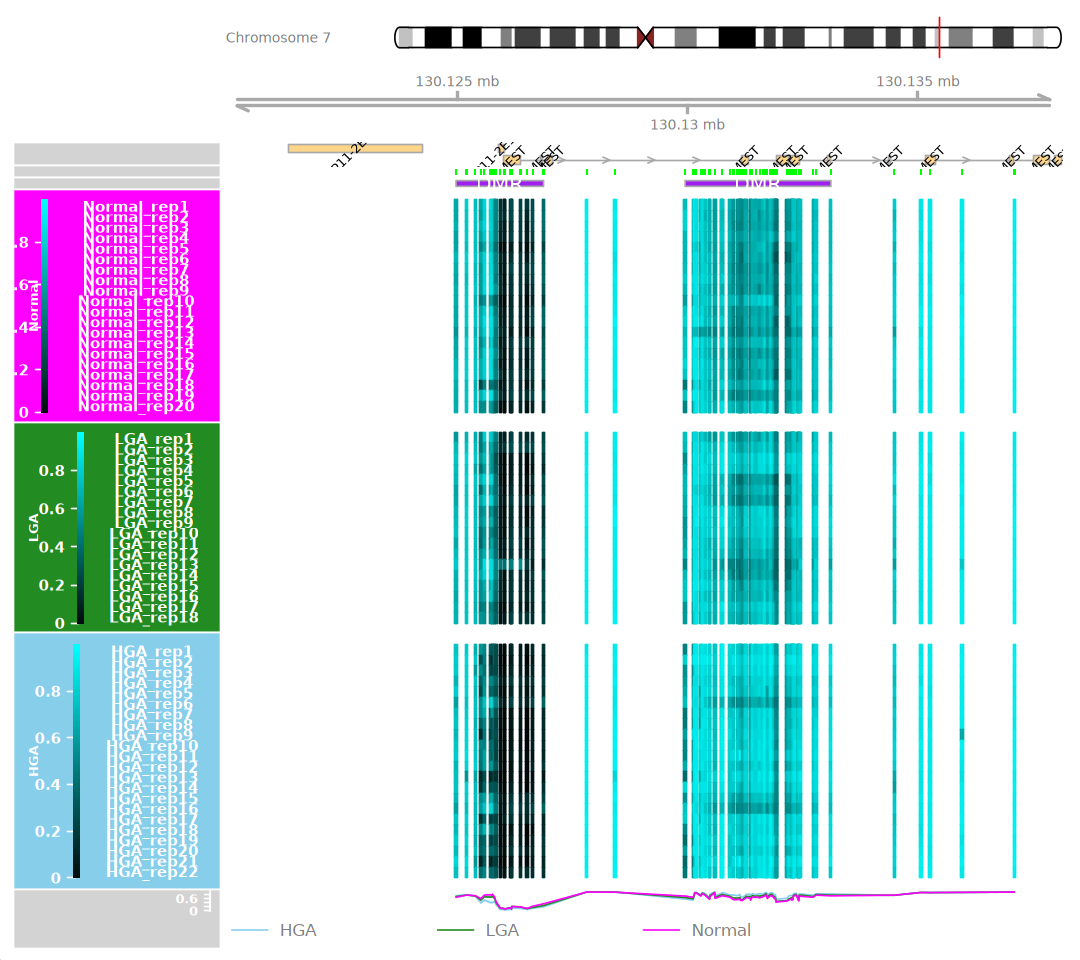

In [54]:
options(repr.plot.width = 9, repr.plot.height = 8)

groups <- c(Normal = "magenta", LGA = "forestgreen", HGA = "skyblue")
cols <- groups[as.character(methySet_filtered$Sample_Group)]

DMR.plot(
    ranges = dmrs_result, dmr = 1, CpGs = cpg_anno, what = "Beta",
    arraytype = "450K", phen.col = cols, genome = "hg19")

### Blocks

In [66]:
design <- model.matrix(
     ~ Sample_Group, data = pData(methySet_filtered))

In [55]:
methySet_collapse <- cpgCollapse(methySet_filtered, what = "M")

[cpgCollapse] Creating annotation.


[cpgCollapseAnnotation] Clustering islands and clusters of probes.


[cpgCollapseAnnotation] Computing new annotation.


[cpgCollapseAnnotation] Defining blocks.


[cpgCollapse] Collapsing data



..........
........


In [56]:
block_result <- blockFinder(
    methySet_collapse$object, design, coef = 3, what = "M",
    cutoff = 0.1, nullMethod = "permutation")

[bumphunterEngine] Using a single core (backend: doSEQ, version: 1.5.2).

[bumphunterEngine] Computing coefficients.

[bumphunterEngine] Smoothing coefficients.

Loading required package: rngtools

[bumphunterEngine] Finding regions.

[bumphunterEngine] Found 4084 bumps.



In [57]:
head(block_result$table)

,chr,start,end,value,area,cluster,indexStart,indexEnd,L,clusterL
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>
2358,chr6,30796478,32515888,-0.4913021,179.8166,314,74938,75521,366,2510
1189,chr1,3361130,7703835,-0.3908666,169.2452,2,1226,2013,433,1400
1342,chr1,151798432,154941277,-0.5766710,159.1612,33,13194,13675,276,1582
1699,chr2,216964242,219151444,-0.6553895,142.8749,98,34993,35273,218,506
1348,chr1,157429016,160336532,-0.6362810,140.6181,33,14218,14533,221,1582
3225,chr11,121542234,124527240,-0.5836285,137.7363,551,135020,135318,236,1675


# 4. ChAMP

> - Yuan Tian, Tiffany J Morris, Amy P Webster, Zhen Yang, Stephan Beck, Andrew Feber, Andrew E Teschendorff, ChAMP: updated methylation analysis pipeline for Illumina BeadChips, Bioinformatics, Volume 33, Issue 24, December 2017, Pages 3982–3984, https://doi.org/10.1093/bioinformatics/btx513.

In [58]:
suppressPackageStartupMessages(library(ChAMP))
suppressPackageStartupMessages(library(ChAMPdata))

No methods found in package 'RSQLite' for request: 'dbListFields' when loading 'lumi'

Warning message:
"replacing previous import 'plyr::mutate' by 'plotly::mutate' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plyr::rename' by 'plotly::rename' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plyr::arrange' by 'plotly::arrange' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plyr::summarise' by 'plotly::summarise' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plotly::subplot' by 'Hmisc::subplot' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plyr::summarize' by 'Hmisc::summarize' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plyr::is.discrete' by 'Hmisc::is.discrete' when loading 'ChAMP'"
Warning message:
"replacing previous import 'plotly::last_plot' by 'ggplot2::last_plot' when loading 'ChAMP'"
Warning message:
"replacing previous import 'globaltest::model.matrix' 

## 1). Data Import and Filtering

> 1. Filter out probes with a p-value greater than 0.01
> 2. Filter out probes with fewer than 3 beads per probe in at least 5% of samples
> 3. Filter out all non-CpG probes
> 4. Filter out all SNP-related probes
> 5. Filter out all multiple-hit probes
> 6. Filter out all probes located on the X and Y chromosomes

In [59]:
myLoad <- champ.load(
    file.path(data_dir, "idat"), method = "minfi", 
    force = TRUE, arraytype = "450K")
# myImport <- champ.import(
#     directory = file.path(data_dir, "idat"), 
#     arraytype = "450K")
# myFilter <-champ.filter(
#     beta = myImport$beta, pd = myImport$pd, 
#     arraytype = "450K")

[===========================]

[<<<< ChAMP.LOAD START >>>>>]

-----------------------------


[ Loading Data with Minfi Method ]

----------------------------------

Loading data from ~/dataset_1/methylation_dataset/array/GSE139404/idat

[read.metharray.sheet] Found the following CSV files:



[1] "/home/fugui/dataset_1/methylation_dataset/array/GSE139404/idat/SampleSheet.csv"


<< Read DataSet Success. >>


The fraction of failed positions per sample
 
            (You may need to delete samples with high proportion of failed probes
): 



           Failed CpG Fraction.
GSM4140633         9.845277e-04
GSM4140634         7.353062e-04
GSM4140635         6.941126e-04
GSM4140636         7.497240e-04
GSM4140637         6.446803e-04
GSM4140638         4.881445e-04
GSM4140639         8.794839e-04
GSM4140640         7.373659e-04
GSM4140641         2.389230e-04
GSM4140642         2.965941e-04
GSM4140643         1.874310e-04
GSM4140644         1.007184e-03
GSM4140645         3.254296e-04
GSM4140646         3.480861e-04
GSM4140647         9.845277e-04
GSM4140648         7.641418e-04
GSM4140649         1.874310e-04
GSM4140650         5.252187e-04
GSM4140651         2.389230e-04
GSM4140652         1.771326e-04
GSM4140653         3.048328e-04
GSM4140654         2.039085e-04
GSM4140655         2.368634e-04
GSM4140656         5.767108e-04
GSM4140657         4.490105e-04
GSM4140658         1.627148e-04
GSM4140659         3.975185e-04
GSM4140660         6.179044e-05
GSM4140661         3.089522e-04
GSM4140662         4.119363e-04
GSM41406

Filtering probes with a detection p-value above 0.01 in one or more samples has removed 2013 probes from the analysis. If a large number of probes have been removed, ChAMP suggests you to identify potentially bad samples.

<< Filter DetP Done. >>



There is no NA values in your matrix, there is no need to imputation.


Filtering probes with a beadcount <3 in at least 5% of samples, has removed 1014 from the analysis.

<< Filter Beads Done. >>


Filtering non-cg probes, has removed 3077 from the analysis.

<< Filter NoCG Done. >>


Using general 450K SNP list for filtering.

Filtering probes with SNPs as identified in Zhou's Nucleic Acids Research Paper, 2016, has removed 58917 from the analysis.

<< Filter SNP Done. >>


Filtering probes that align to multiple locations as identified in Nordlund et al, has removed 11 from the analysis.

<< Filter MultiHit Done. >>


Filtering probes on the X or Y chromosome has removed 9763 from the analysis.

<< Filter XY chromosome Done. >>


[Beta 

In [60]:
names(myLoad)

[1] "mset"      "rgSet"     "pd"        "intensity" "beta"      "detP"

In [61]:
# Generate interactive plot for summary information of a list of CpGs
CpG.GUI(CpG = rownames(myLoad$beta), arraytype = "450K")

Loading required package: shiny


Attaching package: 'shiny'


The following objects are masked from 'package:DT':

    dataTableOutput, renderDataTable



Listening on http://127.0.0.1:4952



## 2). Data Exploration

[===========================]

[<<<<< ChAMP.QC START >>>>>>]

-----------------------------

champ.QC Results will be saved in ~/dataset_1/methylation_dataset/array/GSE139404/ChAMP_QC

[QC plots will be proceed with 410717 probes and 60 samples.]


<< Prepare Data Over. >>

<< plot mdsPlot Done. >>




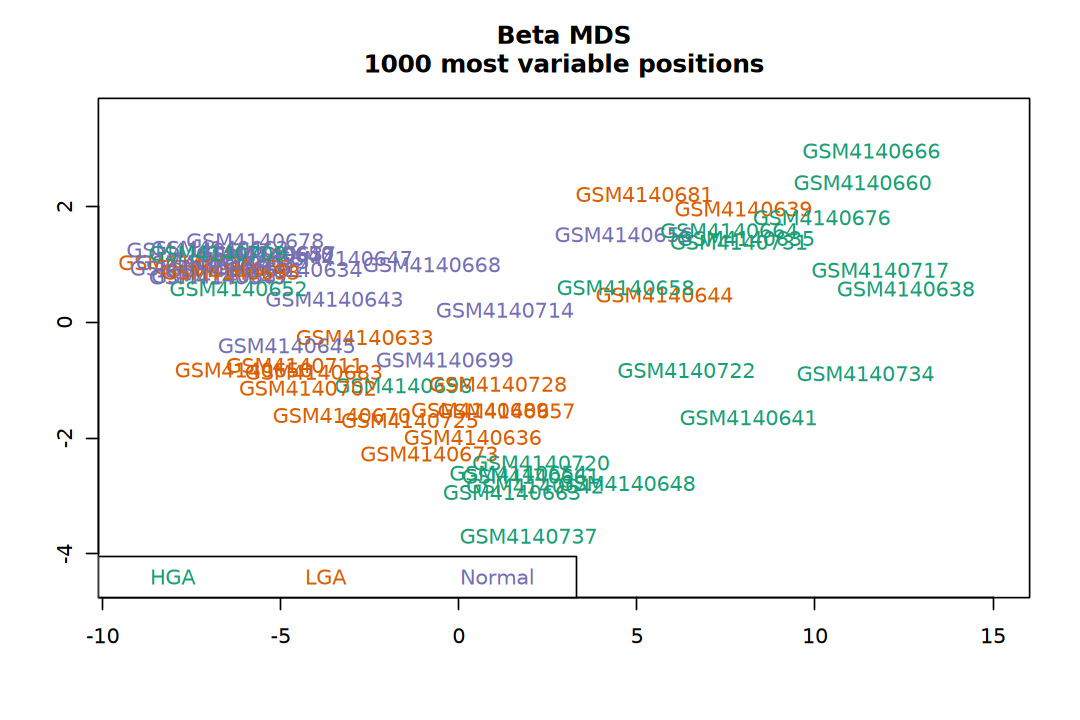

<< Plot densityPlot Done. >>


< Dendrogram Plot Feature Selection Method >: No Selection, directly use all CpGs to calculate distance matrix.



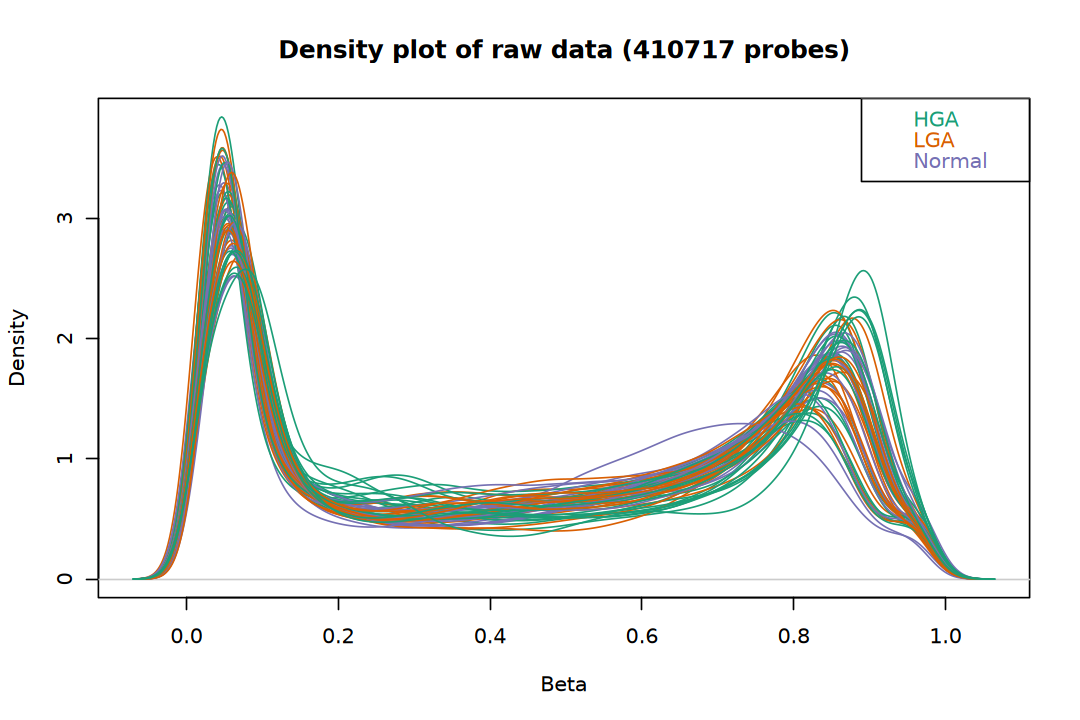

<< Plot dendrogram Done. >>


[<<<<<< ChAMP.QC END >>>>>>>]

[===========================]

[You may want to process champ.norm() next.]




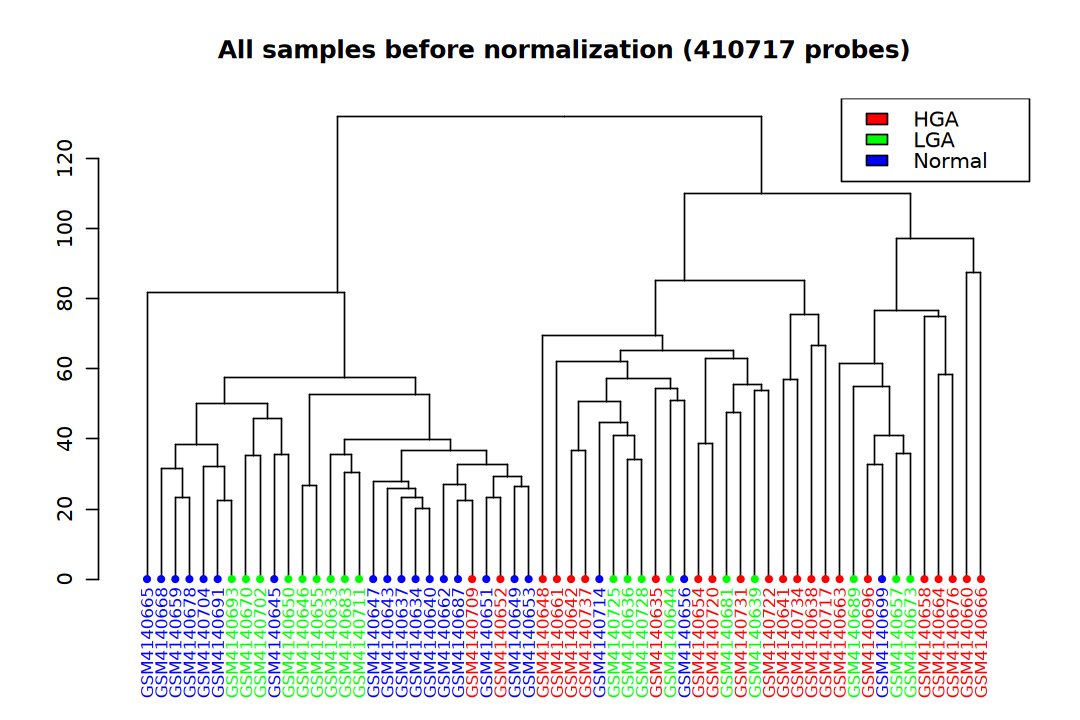

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)
champ.QC(
    beta = myLoad$beta, 
    pheno = myLoad$pd$Sample_Group, 
    resultsDir = file.path(data_dir, "ChAMP_QC"))

In [63]:
QC.GUI(beta = myLoad$beta, pheno = myLoad$pd$Sample_Group, arraytype = "450K")


Listening on http://127.0.0.1:4952



## 3). Normalization

In [64]:
myNorm <- champ.norm(
    rgSet = myLoad$rgSet, 
    method = "FunctionalNormalization", arraytype = "450K", 
    resultsDir = file.path(data_dir, "ChAMP_Normalization"))

[===========================]

[>>>>> ChAMP.NORM START <<<<<<]

-----------------------------

champ.norm Results will be saved in ~/dataset_1/methylation_dataset/array/GSE139404/ChAMP_Normalization

[ SWAN method call for BOTH rgSet and mset input, FunctionalNormalization call for rgset only , while PBC and BMIQ only needs beta value. Please set parameter correctly. ]


[preprocessFunnorm] Background and dye bias correction with noob

[preprocessFunnorm] Mapping to genome

[preprocessFunnorm] Quantile extraction

[preprocessFunnorm] Normalization

[>>>>> ChAMP.NORM END <<<<<<]

[===========================]

[You may want to process champ.SVD() next.]




[===========================]

[<<<<< ChAMP.SVD START >>>>>]

-----------------------------

champ.SVD Results will be saved in ~/dataset_1/methylation_dataset/array/GSE139404/ChAMP_SVD .


Your beta parameter is data.frame format. ChAMP is now changing it to matrix.

[SVD analysis will be proceed with 410717 probes and 60 samples.]



[ champ.SVD() will only check the dimensions between data and pd, instead if checking if Sample_Names are correctly matched (because some user may have no Sample_Names in their pd file),thus please make sure your pd file is in accord with your data sets (beta) and (rgSet).]


<< Following Factors in your pd(sample_sheet.csv) will be analysised: >>

<Sample_Group>(character):LGA, Normal, HGA

<Sample_Gender>(character):female, male

<Array>(character):R01C01, R02C01, R03C01, R04C01, R05C01, R06C01, R01C02, R02C02, R03C02, R04C02, R05C02, R06C02

<Slide>(character):3999442103, 3999442051, 3999442112, 3999442050, 3999442119

[champ.SVD have automatically se

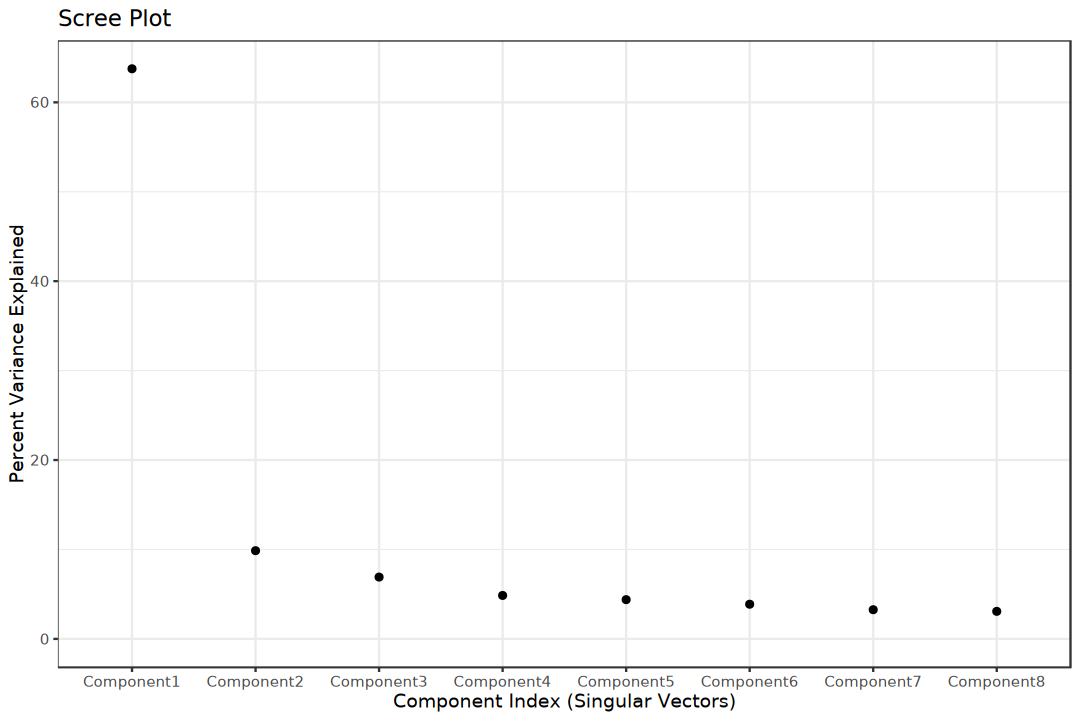

<< Plot SVD matrix successfully. >>

[<<<<<< ChAMP.SVD END >>>>>>]

[===========================]

[If the batch effect is not significant, you may want to process champ.DMP() or champ.DMR() or champ.BlockFinder() next, otherwise, you may want to run champ.runCombat() to eliminat batch effect, then rerun champ.SVD() to check corrected result.]




Sample_Group,Sample_Gender,Array,Slide
8.877631e-08,0.78245726,0.44436265,0.1230543
4.531035e-03,0.02511524,0.62733990,0.4544358
3.844453e-01,0.49970394,0.79289051,0.1070318
1.281282e-01,0.47092467,0.07542042,0.3991718
2.034901e-01,0.53948229,0.83198060,0.4047501
5.950854e-01,0.47092467,0.25596118,0.2902821
2.213201e-02,0.39884010,0.51974374,0.1784273
2.125726e-01,0.80611698,0.08266722,0.1443507


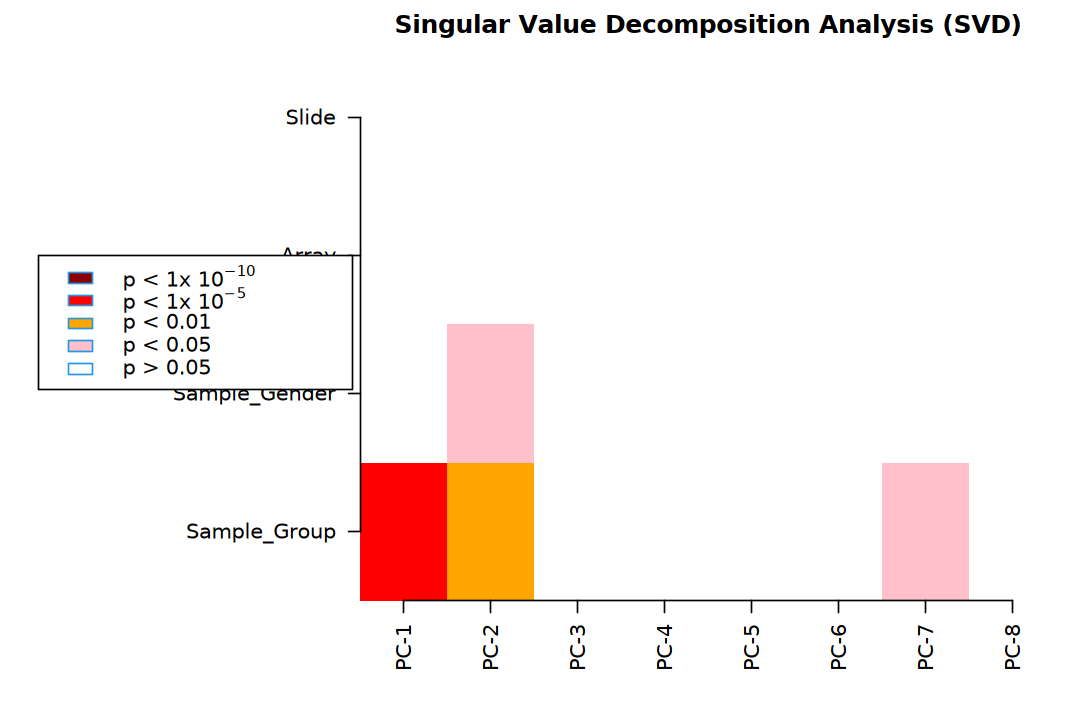

In [65]:
champ.SVD(
    beta = as.data.frame(myNorm), pd = myLoad$pd, 
    resultsDir = file.path(data_dir, "ChAMP_SVD"))
# champ.SVD(
#     beta = as.data.frame(myImpute$beta), rgSet = myLoad$rgSet, pd = myLoad$pd, 
#     RGEffect = TRUE, resultsDir = file.path(data_dir, "ChAMP_SVD"))

## 5). Differentially Analysis

### DMPs (limma)

In [66]:
myDMP <- champ.DMP(
    beta = myNorm, pheno = myLoad$pd$Sample_Group, 
    arraytype = "450K")

[===========================]

[<<<<< ChAMP.DMP START >>>>>]

-----------------------------

!!! Important !!! New Modification has been made on champ.DMP(): 


    (1): In this version champ.DMP() if your pheno parameter contains more than two groups of phenotypes, champ.DMP() would do pairewise differential methylated analysis between each pair of them. But you can also specify compare.group to only do comparasion between any two of them.


    (2): champ.DMP() now support numeric as pheno, and will do linear regression on them. So covariates like age could be inputted in this function. You need to make sure your inputted "pheno" parameter is "numeric" type.


--------------------------------


[ Section 1:  Check Input Pheno Start ]


  You pheno is character type.

    Your pheno information contains following groups. >>

    <LGA>:18 samples.

    <Normal>:20 samples.

    <HGA>:22 samples.

    [The power of statistics analysis on groups contain very few samples may not strong.]


         Contrasts
Levels    pNormal-pLGA
  pLGA              -1
  pNormal            1


  You have found 72817 significant MVPs with a BH adjusted P-value below 0.05.

  Calculate DMP for LGA and Normal done.

  -----------------------------

  Start to Compare : LGA, HGA

  Contrast Matrix



      Contrasts
Levels pLGA-pHGA
  pHGA        -1
  pLGA         1


  You have found 68772 significant MVPs with a BH adjusted P-value below 0.05.

  Calculate DMP for LGA and HGA done.

  -----------------------------

  Start to Compare : Normal, HGA

  Contrast Matrix



         Contrasts
Levels    pNormal-pHGA
  pHGA              -1
  pNormal            1


  You have found 168158 significant MVPs with a BH adjusted P-value below 0.05.

  Calculate DMP for Normal and HGA done.


[ Section 2:  Find Numeric Vector Related CpGs Done ]



[ Section 3:  Match Annotation Start ]



[ Section 3:  Match Annotation Done ]


[<<<<<< ChAMP.DMP END >>>>>>]

[===========================]

[You may want to process DMP.GUI() or champ.GSEA() next.]




In [67]:
myDMP[[1]] |> head()

,logFC,AveExpr,t,P.Value,adj.P.Val,B,LGA_AVG,Normal_AVG,deltaBeta,CHR,⋯,gene,feature,cgi,feat.cgi,UCSC_CpG_Islands_Name,DHS,Enhancer,Phantom,Probe_SNPs,Probe_SNPs_10
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,⋯,<fct>,<chr>,<fct>,<fct>,<fct>,<lgl>,<lgl>,<fct>,<fct>,<fct>
cg25747017,0.21908377,0.6924899,7.657609,3.824694e-09,0.001570867,10.330123,0.5771826,0.7962664,0.21908377,18,⋯,KIAA0802,Body,shore,Body-shore,chr18:8785433-8785644,NA,TRUE,,,
cg22172309,0.14833122,0.7677036,6.884254,4.032558e-08,0.002731560,7.965243,0.6896345,0.8379657,0.14833122,4,⋯,NEK1,Body,opensea,Body-opensea,,NA,NA,,,
cg07857040,-0.08735444,0.7911648,-6.864461,4.285905e-08,0.002731560,7.904166,0.8371409,0.7497864,-0.08735444,16,⋯,IFT140,Body,shore,Body-shore,chr16:1583809-1584641,NA,NA,,,
cg20464155,-0.07931112,0.7828272,-6.798490,5.251999e-08,0.002731560,7.700441,0.8245699,0.7452588,-0.07931112,1,⋯,,IGR,opensea,IGR-opensea,,TRUE,TRUE,,,
cg26681176,-0.09000404,0.7350875,-6.763577,5.849210e-08,0.002731560,7.592531,0.7824581,0.6924540,-0.09000404,14,⋯,KCNK10,Body,opensea,Body-opensea,,NA,NA,,,
cg10941185,-0.08703542,0.7162704,-6.696239,7.201235e-08,0.002731560,7.384227,0.7620785,0.6750431,-0.08703542,8,⋯,DLC1,Body,shore,Body-shore,chr8:12989380-12989635,NA,NA,,,


In [68]:
DMP.GUI(DMP = myDMP[[1]], beta = myNorm, pheno = myLoad$pd$Sample_Group)


Listening on http://127.0.0.1:4952



### DMRs (minfi, DMRcate)

In [69]:
# !DMRcate error.
myDMR <- champ.DMR(
    beta = myNorm, pheno = myLoad$pd$Sample_Group, 
    method = "Bumphunter", arraytype = "450K")

[===========================]

[<<<<< ChAMP.DMR START >>>>>]

-----------------------------

!!! important !!! We just upgrate champ.DMR() function, since now champ.DMP() could works on multiple phenotypes, but ProbeLasso can only works on one DMP result, so if your pheno parameter contains more than 2 phenotypes, and you want to use ProbeLasso function, you MUST specify compare.group=c("A","B"). Bumphunter and DMRcate should not be influenced.


[ Section 1:  Check Input Pheno Start ]


  You pheno is character type.

    Your pheno information contains following groups. >>

    <LGA>:18 samples.

    <Normal>:20 samples.

    <HGA>:22 samples.


[ Section 1:  Check Input Pheno Done ]



[ Section 2:  Run DMR Algorithm Start ]


<< Find DMR with Bumphunter Method >>

3 cores will be used to do parallel Bumphunter computing.

According to your data set, champ.DMR() detected 8555 clusters contains MORE THAN 7 probes within300 maxGap. These clusters will be used to find DMR.


[bumphunte

In [70]:
myDMP[[1]] |> head()

,logFC,AveExpr,t,P.Value,adj.P.Val,B,LGA_AVG,Normal_AVG,deltaBeta,CHR,⋯,gene,feature,cgi,feat.cgi,UCSC_CpG_Islands_Name,DHS,Enhancer,Phantom,Probe_SNPs,Probe_SNPs_10
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,⋯,<fct>,<chr>,<fct>,<fct>,<fct>,<lgl>,<lgl>,<fct>,<fct>,<fct>
cg25747017,0.21908377,0.6924899,7.657609,3.824694e-09,0.001570867,10.330123,0.5771826,0.7962664,0.21908377,18,⋯,KIAA0802,Body,shore,Body-shore,chr18:8785433-8785644,NA,TRUE,,,
cg22172309,0.14833122,0.7677036,6.884254,4.032558e-08,0.002731560,7.965243,0.6896345,0.8379657,0.14833122,4,⋯,NEK1,Body,opensea,Body-opensea,,NA,NA,,,
cg07857040,-0.08735444,0.7911648,-6.864461,4.285905e-08,0.002731560,7.904166,0.8371409,0.7497864,-0.08735444,16,⋯,IFT140,Body,shore,Body-shore,chr16:1583809-1584641,NA,NA,,,
cg20464155,-0.07931112,0.7828272,-6.798490,5.251999e-08,0.002731560,7.700441,0.8245699,0.7452588,-0.07931112,1,⋯,,IGR,opensea,IGR-opensea,,TRUE,TRUE,,,
cg26681176,-0.09000404,0.7350875,-6.763577,5.849210e-08,0.002731560,7.592531,0.7824581,0.6924540,-0.09000404,14,⋯,KCNK10,Body,opensea,Body-opensea,,NA,NA,,,
cg10941185,-0.08703542,0.7162704,-6.696239,7.201235e-08,0.002731560,7.384227,0.7620785,0.6750431,-0.08703542,8,⋯,DLC1,Body,shore,Body-shore,chr8:12989380-12989635,NA,NA,,,


In [71]:
DMR.GUI(
    DMR = myDMR, beta = myNorm, pheno = myLoad$pd$Sample_Group, 
    runDMP = FALSE, arraytype = "450K")

!!! important !!! Since we just upgrated champ.DMP() function, which is now can support multiple phenotypes. Here in DMR.GUI() function, if you want to use "runDMP" parameter, and your pheno contains more than two groups of phenotypes, you MUST specify compare.group parameter as compare.group=c("A","B") to get DMP value between group A and group B.


[ Section 1: Calculate DMP Start  ]



[ Section 1: Calculate DMP Done  ]





[ Section 2: Mapping DMR to annotation Start  ]


  Generating Annotation File

  Generating Annotation File Success


[ Section 2: Mapping DMR to annotation Done  ]



Listening on http://127.0.0.1:4952



### Blocks

In [72]:
myBlock <- champ.Block(
    beta = myNorm, pheno = myLoad$pd$Sample_Group, 
    arraytype = "450K", core = 4)

[===========================]

[<<<< ChAMP.Block START >>>>]

-----------------------------



<< Load Annotation Successfully >>

<< Get Clusters by cgi-info Successfully >>

<< Calculate Average Beta Value Successfully >>

<< Generate Block Position Successfully >>

<< New Clusters are generated for blocks >>

<< Generate information for New Clusters >>

[bumphunterEngine] Parallelizing using 4 workers/cores (backend: doParallelMC, version: 1.0.17).

[bumphunterEngine] Computing coefficients.

[bumphunterEngine] Smoothing coefficients.

[bumphunterEngine] Performing 500 permutations.

[bumphunterEngine] Computing marginal permutation p-values.

[bumphunterEngine] Smoothing permutation coefficients.

[bumphunterEngine] cutoff: 0.005

[bumphunterEngine] Finding regions.

[bumphunterEngine] Found 2615 bumps.

[bumphunterEngine] Computing regions for each permutation.

[bumphunterEngine] Estimating p-values and FWER.

<< Run Bumphunter Successfully >>

[<<<<< ChAMP.BLOCK END >>>>>]

[===========================]

[You may want to process Block.GUI() next.]




In [73]:
myBlock[[1]] |> head()

,chr,start,end,value,area,cluster,indexStart,indexEnd,L,clusterL,p.value,fwer,p.valueArea,fwerArea
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Block_1,11,121502395,129014781,0.03893046,20.74994,700,20865,21397,533,1552,0,0,0,0
Block_2,2,217009673,224069430,0.03876663,15.27405,141,54347,54740,394,467,0,0,0,0
Block_3,1,2194050,7757376,0.02212238,12.89735,2,128,710,583,1294,0,0,0,0
Block_4,11,4159839,8662007,0.03969700,12.38546,663,16020,16331,312,1356,0,0,0,0
Block_5,6,30449260,33838308,0.02323821,11.80501,401,77184,77691,508,1908,0,0,0,0
Block_6,1,151701251,156378026,0.03256655,11.26802,44,5844,6189,346,502,0,0,0,0


In [74]:
Block.GUI(
    Block = myBlock, beta = myNorm, pheno = myLoad$pd$Sample_Group, 
    runDMP = FALSE, compare.group = NULL, arraytype = "450K")

!!! important !!! Since we just upgrated champ.DMP() function, which is now can support multiple phenotypes. Here in Block.GUI() function, if you want to use "runDMP" parameter, and your pheno contains more than two groups of phenotypes, you MUST specify compare.group parameter as compare.group=c("A","B") to get DMP value between group A and group B.



Generation CpG information


Listening on http://127.0.0.1:4952



---

# Reference

> 1. [Bioconductor workflow: methylationArrayAnalysis](https://www.bioconductor.org/packages/release/workflows/html/methylationArrayAnalysis.html)
> 2. [ChAMP: The Chip Analysis Methylation Pipeline](https://bioconductor.org/packages/release/bioc/vignettes/ChAMP/inst/doc/ChAMP.html)